# Set 11.1: Train a U-Net to segment food on hospital trays

Based on the course notebook `unet_tray_food_segmentation.ipynb`: a small U-Net, trained from scratch in PyTorch, finds
the **food** on images of meal trays (binary task: food vs. not food), and the **Dice coefficient** measures the result.

**How to use this notebook** (it runs locally, on the GPU of the computer; a CPU also works, only slower):

1. Unzip `TrayDataset.zip` (Set 10-11 materials, [Kaggle: thezaza102/tray-food-segmentation](https://www.kaggle.com/datasets/thezaza102/tray-food-segmentation))
   into `datasets/`, so the folders are `datasets/TrayDataset/XTrain`, `yTrain`, `XTest`, `yTest`.
2. The ONNX export needs two packages the app does not: `uv pip install --python .venv/Scripts/python.exe onnx onnxscript`
3. Run all cells with the `.venv` kernel. Training takes about a minute on an RTX 3050 Laptop.

At the end the trained model is saved in `models/` as three files:

| File | What it is |
|---|---|
| `tray_food_unet.pt` | the best weights (PyTorch `state_dict` of the `UNet` class below) |
| `tray_food_unet.onnx` | the same network in ONNX, which the app runs with OpenCV (no PyTorch needed) |
| `tray_food_unet_passport.json` | the **model passport**: dataset, classes, preprocessing, training and test Dice |

In [1]:
import copy
import csv
import datetime
import json
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "datasets" / "TrayDataset"
MODELS_DIR = ROOT / "models"
MODEL_NAME = "tray_food_unet"

SEED = 42
FIRST_FOOD = 5  # class index of 'meatball', the first food class
H, W = 128, 208  # must be divisible by 8 (the U-Net downsamples 3 times); keeps the trays' aspect ratio
BATCH = 16
EPOCHS = 15
LEARNING_RATE = 1e-3
VALIDATION = 0.15
THRESHOLD = 0.5

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

PyTorch 2.15.0+cu132 | device: NVIDIA GeForce RTX 3050 Laptop GPU


## 1. The dataset

`XTrain` / `yTrain` hold the training images and their masks, `XTest` / `yTest` the test ones. Each mask stores, for
every pixel, the **index of its class**: 0 = background, 1 = tray, 2 = cutlery, ... up to 42 food and drink classes
(`classes.csv`). An image and its mask share the file name.

In [2]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}


def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)


def pair_files(img_dir, mask_dir):
    # Match each image with its mask using the file name (without extension)
    masks = {p.stem: p for p in list_images(mask_dir)}
    return [(p, masks[p.stem]) for p in list_images(img_dir) if p.stem in masks]


def read_mask(path):
    m = np.array(Image.open(path))
    return m[..., 0] if m.ndim == 3 else m  # some masks are saved with 3 identical channels


with open(DATA_DIR / "classes.csv", encoding="utf-8-sig", newline="") as f:
    CLASS_NAMES = [row["_name"] for row in csv.DictReader(f)]

train_pairs = pair_files(DATA_DIR / "XTrain", DATA_DIR / "yTrain")
test_pairs = pair_files(DATA_DIR / "XTest", DATA_DIR / "yTest")
print(f"{len(train_pairs)} training pairs, {len(test_pairs)} test pairs, {len(CLASS_NAMES)} classes")
print("Not food:", CLASS_NAMES[:FIRST_FOOD])
print("Food:", CLASS_NAMES[FIRST_FOOD:])

1241 training pairs, 8 test pairs, 43 classes
Not food: ['background', 'tray', 'cutlery', 'form', 'straw']
Food: ['meatball', 'beef', 'roast lamb', 'beef tomato casserole', 'ham', 'bean', 'cucumber', 'leaf', 'tomato', 'boiled rice', 'beef mexican meatballs', 'spinach and pumpkin risotto', 'baked fish', 'gravy', 'zucchini', 'carrot', 'broccoli', 'pumpkin', 'celery', 'sandwich', 'side salad', 'tartare sauce', 'jacket potato', 'creamed potato', 'bread', 'margarine', 'soup', 'apple', 'canned fruit', 'milk', 'vanilla yogurt', 'jelly', 'custard', 'lemon sponge', 'juice', 'apple juice', 'orange juice', 'water']


Image: (256, 416, 3) | Mask: (256, 416) | values in mask: [ 0  1  2  7 18 19 22 27 31 37 41]
Classes present: ['background', 'tray', 'cutlery', 'roast lamb', 'gravy', 'zucchini', 'pumpkin', 'jacket potato', 'soup', 'custard', 'orange juice']


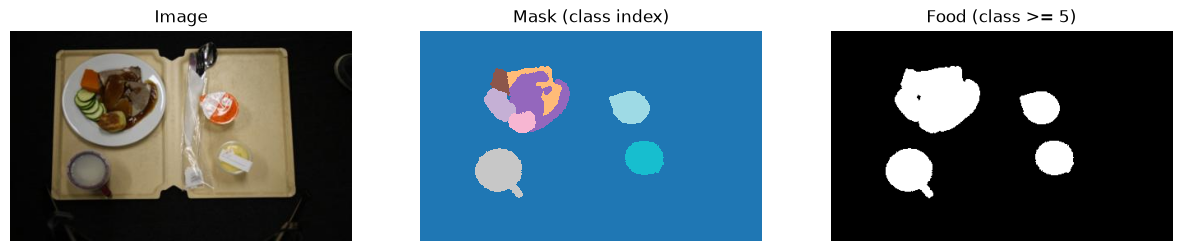

In [3]:
img_path, mask_path = train_pairs[0]
img, mask = np.array(Image.open(img_path).convert("RGB")), read_mask(mask_path)
print("Image:", img.shape, "| Mask:", mask.shape, "| values in mask:", np.unique(mask))
print("Classes present:", [CLASS_NAMES[v] for v in np.unique(mask)])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(img); ax[0].set_title("Image")
ax[1].imshow(mask, cmap="tab20", interpolation="nearest"); ax[1].set_title("Mask (class index)")
ax[2].imshow(mask >= FIRST_FOOD, cmap="gray"); ax[2].set_title("Food (class >= 5)")
for a in ax:
    a.axis("off")
plt.show()

## 2. The task: food vs. not food

With 43 classes and only ~1,200 images a tiny network would struggle, so the classes are merged into a **binary**
problem, as in the course notebook: **0 = not food** (background, tray, cutlery, form, straw: classes 0 to 4) and
**1 = food** (every class from 5 on). Images are resized to 128 × 208 (bilinear) and masks too, with **nearest**
interpolation so no new class values are invented. Everything fits in memory, which makes training fast.

In [4]:
def load_pairs(pairs):
    X = np.zeros((len(pairs), H, W, 3), dtype=np.uint8)
    Y = np.zeros((len(pairs), H, W), dtype=np.uint8)
    for i, (ip, mp) in enumerate(pairs):
        X[i] = np.array(Image.open(ip).convert("RGB").resize((W, H), Image.BILINEAR))
        Y[i] = np.array(Image.fromarray(read_mask(mp)).resize((W, H), Image.NEAREST))
    return X, (Y >= FIRST_FOOD).astype(np.uint8)


X_all, Y_all = load_pairs(train_pairs)
X_test, Y_test = load_pairs(test_pairs)
print(f"train+val: {X_all.shape} | test: {X_test.shape} | food pixels: {Y_all.mean():.1%}")

train+val: (1241, 128, 208, 3) | test: (8, 128, 208, 3) | food pixels: 10.6%


15% of the training images are kept for **validation** (to choose the best epoch); the test folder is used only at the
end. Augmentation: a random horizontal flip of the image **and** its mask.

In [5]:
idx = np.random.permutation(len(X_all))
n_val = int(VALIDATION * len(idx))
val_idx, train_idx = idx[:n_val], idx[n_val:]


class TrayDataset(Dataset):
    def __init__(self, X, Y, augment=False):
        self.X, self.Y, self.augment = X, Y, augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0  # (3, H, W) in [0, 1]
        y = torch.from_numpy(self.Y[i]).float().unsqueeze(0)  # (1, H, W) in {0, 1}
        if self.augment and random.random() < 0.5:
            x, y = x.flip(-1), y.flip(-1)
        return x, y


train_dl = DataLoader(TrayDataset(X_all[train_idx], Y_all[train_idx], augment=True), batch_size=BATCH, shuffle=True)
val_dl = DataLoader(TrayDataset(X_all[val_idx], Y_all[val_idx]), batch_size=BATCH)
test_dl = DataLoader(TrayDataset(X_test, Y_test), batch_size=BATCH)
print(f"train: {len(train_idx)} | val: {n_val} | test: {len(X_test)}")

train: 1055 | val: 186 | test: 8


## 3. The U-Net

The **encoder** applies convolutions and max-pooling: the image gets smaller and the channels grow, so the network
learns *what* is in the image. The **decoder** upsamples back to the input size to say *where*. **Skip connections**
copy the encoder features to the decoder at the same resolution, giving back the details lost by pooling.

```
input (3×128×208)
  enc1 ─────────────────────────────► dec1 ─► 1×1 conv ─► output (1×128×208), one logit per pixel
    │ pool                              ▲ up
    enc2 ───────────────────────► dec2
      │ pool                        ▲ up
      enc3 ─────────────────► dec3
        │ pool                ▲ up
        └──── bottleneck ─────┘
```

In [6]:
def conv_block(in_ch, out_ch):
    # Two 3x3 convolutions, each followed by BatchNorm and ReLU
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8
        self.enc1, self.enc2, self.enc3 = conv_block(in_ch, c1), conv_block(c1, c2), conv_block(c2, c3)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = conv_block(c3, c4)
        # Decoder: upsample, concatenate the skip connection, then convolve
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, stride=2), conv_block(c3 * 2, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, stride=2), conv_block(c2 * 2, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, stride=2), conv_block(c1 * 2, c1)
        self.head = nn.Conv2d(c1, out_ch, 1)  # one score (logit) per pixel

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)


model = UNet().to(device)
PARAMETERS = sum(p.numel() for p in model.parameters())
print(f"Parameters: {PARAMETERS:,}")
print("Output shape:", model(torch.zeros(1, 3, H, W, device=device)).shape)

Parameters: 482,737


Output shape: torch.Size([1, 1, 128, 208])


## 4. The Dice coefficient

$$\text{Dice}(P, G) = \frac{2\,|P \cap G|}{|P| + |G|}$$

1 when the predicted mask $P$ and the ground truth $G$ match, 0 when they do not overlap. Unlike pixel accuracy it is
not fooled by the large background: predicting "no food" everywhere gets ~90% accuracy but Dice 0.

* **Hard Dice** (thresholded 0/1 masks) is the **evaluation metric**.
* **Soft Dice** (probabilities) is differentiable, so `1 − soft Dice` is part of the **loss**, together with binary
  cross-entropy.

In [7]:
def dice_coef(pred, target, eps=1e-6):
    # pred, target: (B, 1, H, W) with values in [0, 1]. Returns one Dice per image.
    inter = (pred * target).sum(dim=(1, 2, 3))
    total = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (2 * inter + eps) / (total + eps)


def loss_fn(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    soft_dice = dice_coef(torch.sigmoid(logits), target).mean()
    return bce + (1 - soft_dice)


@torch.no_grad()
def evaluate(model, loader, threshold=THRESHOLD):
    model.eval()
    dices, losses = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        losses.append(loss_fn(logits, y).item() * len(x))
        dices.append(dice_coef((torch.sigmoid(logits) > threshold).float(), y).cpu())
    return torch.cat(dices).numpy(), sum(losses) / len(loader.dataset)  # Dice for every image, mean loss


P = np.array([[0, 1, 1, 0], [0, 1, 1, 0], [0, 0, 0, 0], [0, 0, 0, 0]])
G = np.array([[0, 0, 1, 1], [0, 0, 1, 1], [0, 0, 0, 0], [0, 0, 0, 0]])
print(f"Toy example: Dice = {2 * (P * G).sum() / (P.sum() + G.sum()):.2f} vs pixel accuracy = {(P == G).mean():.2f}")

Toy example: Dice = 0.50 vs pixel accuracy = 0.75


## 5. Training

Adam, keeping the weights of the epoch with the best **validation Dice**.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"loss": [], "val_loss": [], "val_dice": []}
best_dice, best_epoch, best_state = 0.0, 0, None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, running = time.time(), 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(x)

    val_dices, val_loss = evaluate(model, val_dl)
    history["loss"].append(running / len(train_dl.dataset))
    history["val_loss"].append(val_loss)
    history["val_dice"].append(float(val_dices.mean()))
    if val_dices.mean() > best_dice:
        best_dice, best_epoch, best_state = float(val_dices.mean()), epoch, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d} | loss {history['loss'][-1]:.3f} | val loss {val_loss:.3f} | "
          f"val Dice {val_dices.mean():.3f} | {time.time() - t0:.0f}s")

TRAIN_MINUTES = (time.time() - start) / 60
model.load_state_dict(best_state)
print(f"Best validation Dice: {best_dice:.3f} (epoch {best_epoch}), trained in {TRAIN_MINUTES:.1f} min")

Epoch  1 | loss 1.124 | val loss 0.968 | val Dice 0.761 | 5s


Epoch  2 | loss 0.797 | val loss 0.684 | val Dice 0.900 | 4s


Epoch  3 | loss 0.550 | val loss 0.460 | val Dice 0.912 | 4s


Epoch  4 | loss 0.372 | val loss 0.335 | val Dice 0.916 | 4s


Epoch  5 | loss 0.256 | val loss 0.220 | val Dice 0.932 | 4s


Epoch  6 | loss 0.185 | val loss 0.208 | val Dice 0.920 | 4s


... (5 outputs left out)

Epoch 12 | loss 0.088 | val loss 0.133 | val Dice 0.931 | 4s


Epoch 13 | loss 0.089 | val loss 0.089 | val Dice 0.957 | 5s


Epoch 14 | loss 0.075 | val loss 0.083 | val Dice 0.958 | 5s


Epoch 15 | loss 0.073 | val loss 0.088 | val Dice 0.955 | 4s
Best validation Dice: 0.958 (epoch 14), trained in 1.1 min


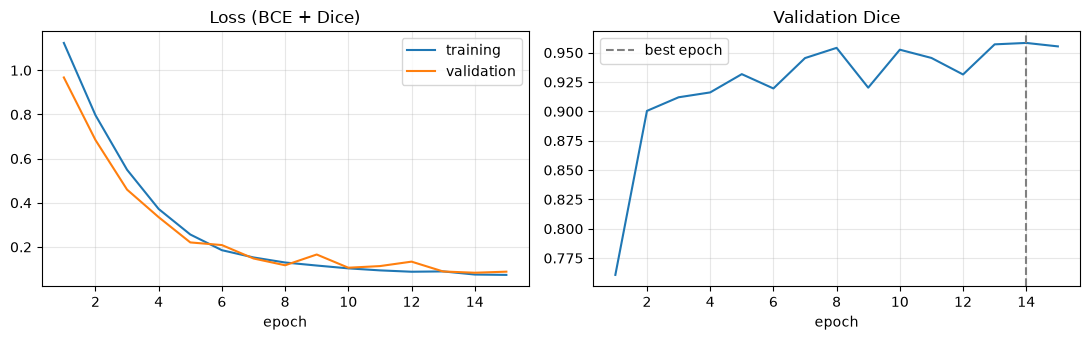

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
epochs = range(1, EPOCHS + 1)
ax[0].plot(epochs, history["loss"], label="training"); ax[0].plot(epochs, history["val_loss"], label="validation")
ax[0].set_title("Loss (BCE + Dice)"); ax[0].legend()
ax[1].plot(epochs, history["val_dice"]); ax[1].axvline(best_epoch, color="gray", ls="--", label="best epoch")
ax[1].set_title("Validation Dice"); ax[1].legend()
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Evaluation on the test set

The 8 test images were never used for training or for choosing the best epoch.

In [10]:
test_dice, test_loss = evaluate(model, test_dl)
print(f"Test Dice: {test_dice.mean():.3f} ± {test_dice.std():.3f}  (n = {len(test_dice)} images)")
for (image_path, _), d in zip(test_pairs, test_dice):
    print(f"  {image_path.name}: {d:.3f}")

Test Dice: 0.944 ± 0.028  (n = 8 images)
  1005a.jpg: 0.961
  2002a.jpg: 0.967
  3004a.jpg: 0.896
  4003a.jpg: 0.970
  5006a.jpg: 0.904
  6004a.jpg: 0.955
  7010a.jpg: 0.927
  8006a.jpg: 0.969


Image, ground truth, prediction and the prediction overlaid on the image (as in the slides), for every test image.

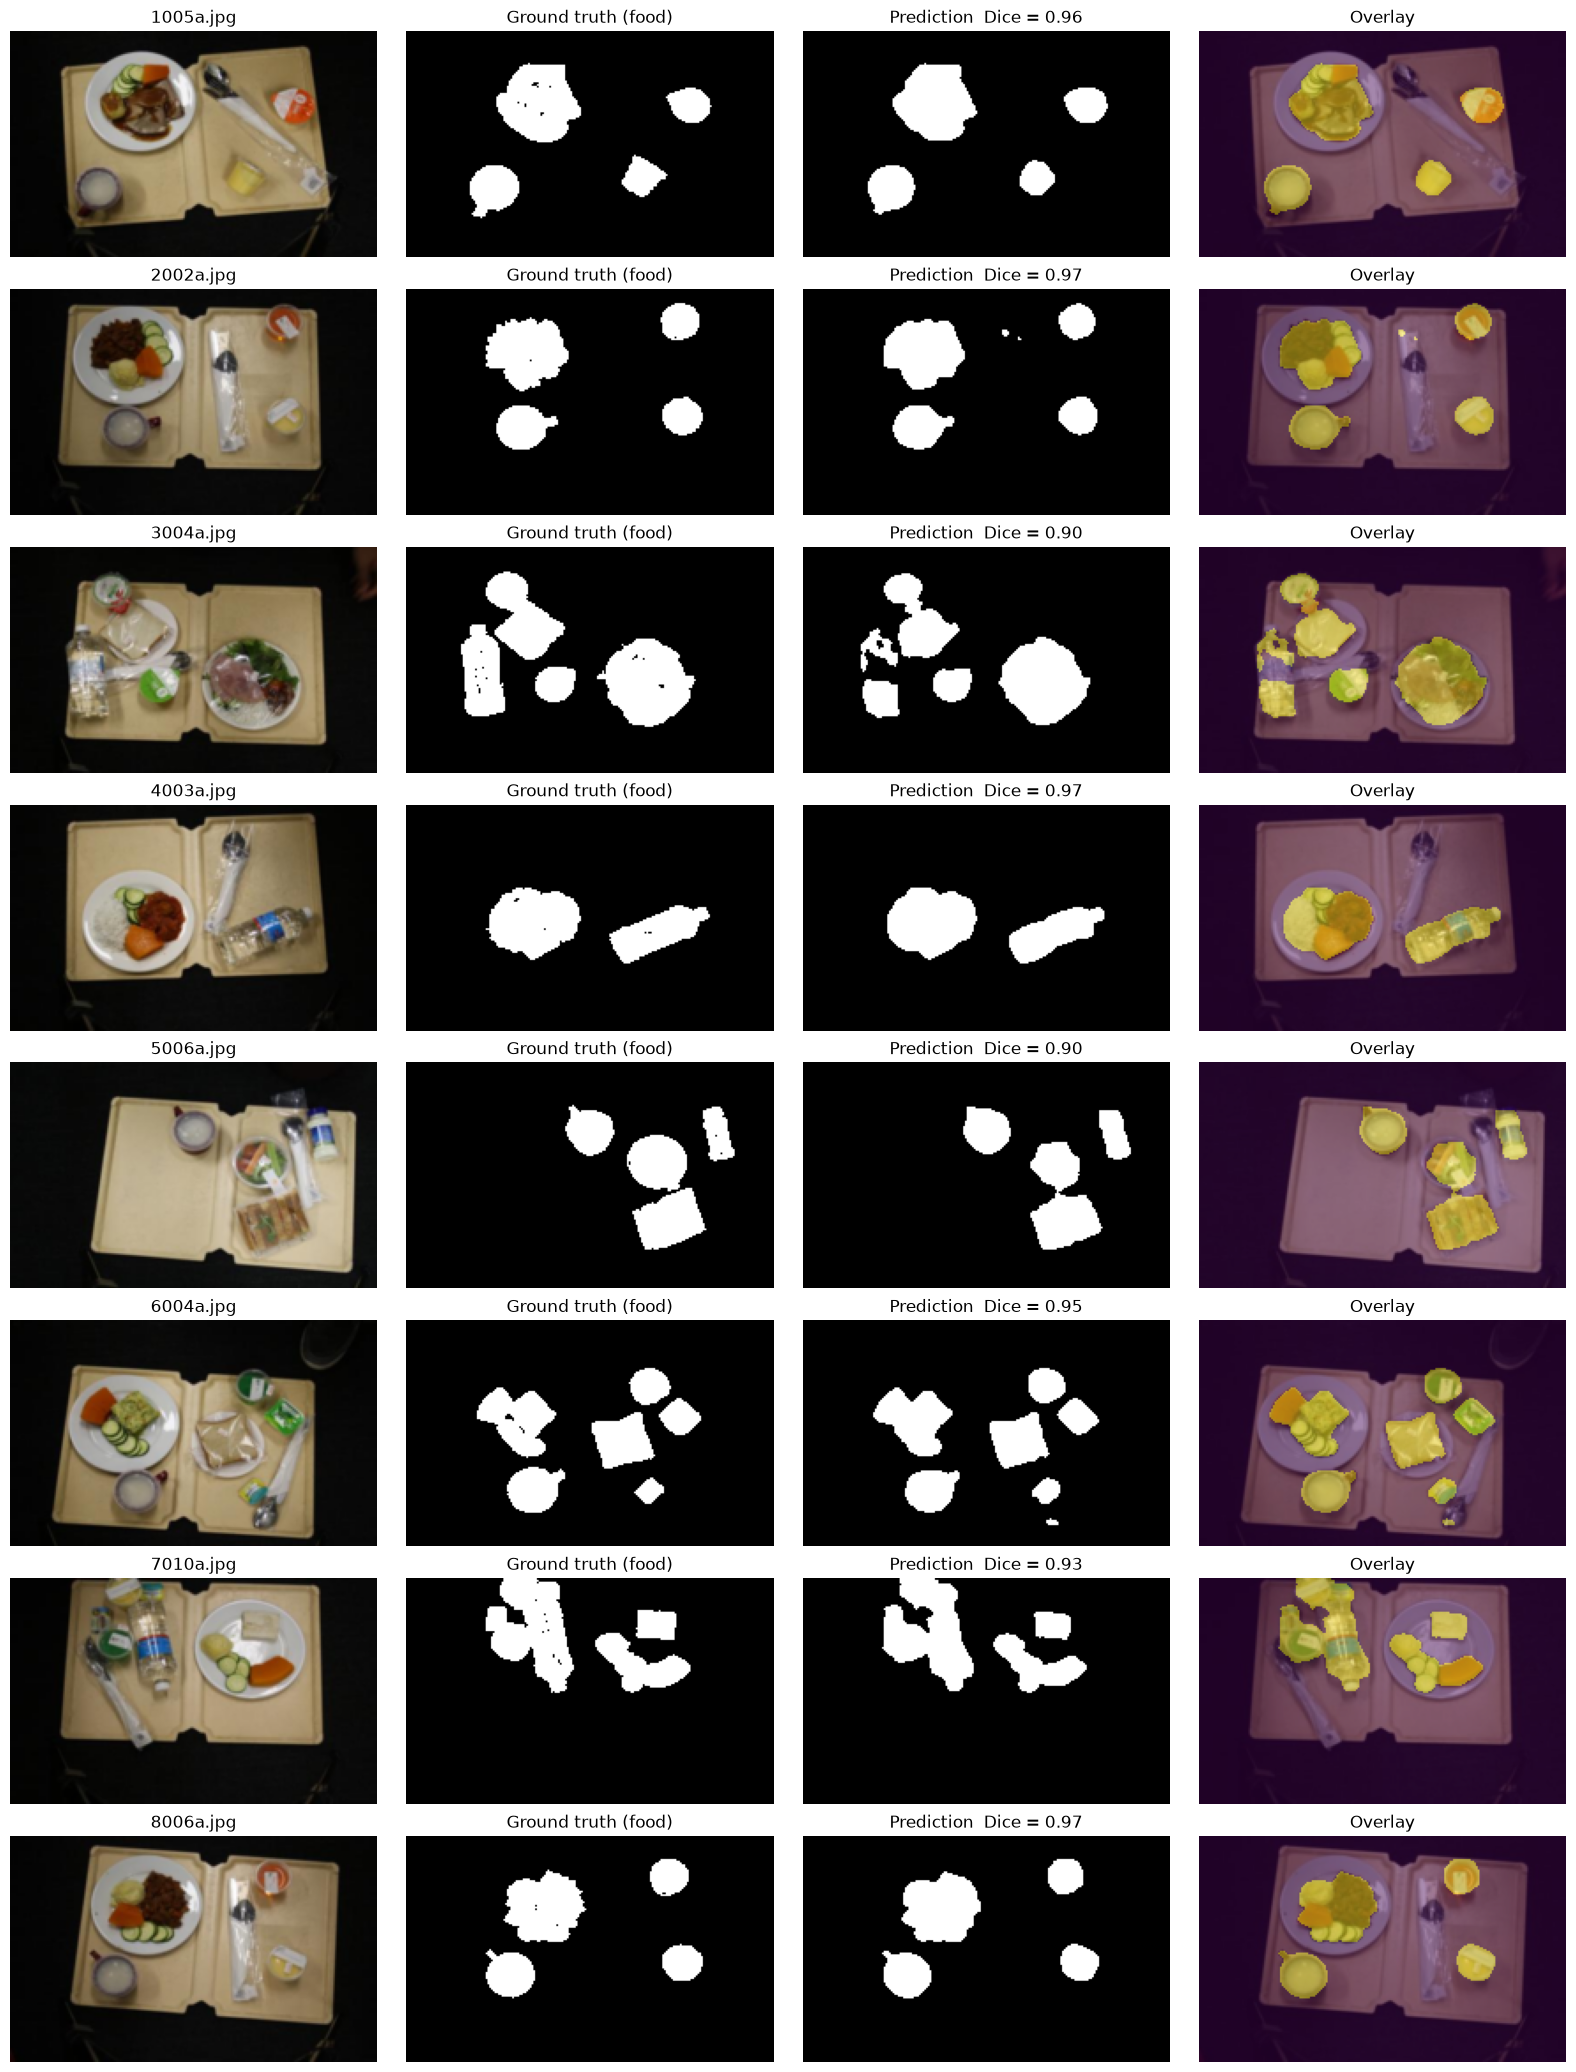

In [11]:
@torch.no_grad()
def predict(x):
    model.eval()
    x = torch.from_numpy(x).permute(2, 0, 1).float().div(255).unsqueeze(0).to(device)
    return torch.sigmoid(model(x))[0, 0].cpu().numpy()


fig, ax = plt.subplots(len(X_test), 4, figsize=(16, 2.6 * len(X_test)), squeeze=False)
for r in range(len(X_test)):
    probability = predict(X_test[r])
    pred = probability > THRESHOLD
    ax[r, 0].imshow(X_test[r]); ax[r, 0].set_title(test_pairs[r][0].name)
    ax[r, 1].imshow(Y_test[r], cmap="gray"); ax[r, 1].set_title("Ground truth (food)")
    ax[r, 2].imshow(pred, cmap="gray"); ax[r, 2].set_title(f"Prediction  Dice = {test_dice[r]:.2f}")
    ax[r, 3].imshow(X_test[r]); ax[r, 3].imshow(pred, cmap="viridis", alpha=0.45); ax[r, 3].set_title("Overlay")
    for a in ax[r]:
        a.axis("off")
plt.tight_layout(); plt.show()

## 7. Save weights, ONNX and passport

The ONNX file has a fixed input of 1 × 3 × 128 × 208 (RGB divided by 255) and outputs one logit per pixel; the app
applies the sigmoid and the threshold. The last cell checks that OpenCV's DNN module gives the same output as PyTorch.

In [12]:
MODELS_DIR.mkdir(exist_ok=True)
weights_path = MODELS_DIR / f"{MODEL_NAME}.pt"
onnx_path = MODELS_DIR / f"{MODEL_NAME}.onnx"
torch.save(model.state_dict(), weights_path)

model_cpu = copy.deepcopy(model).cpu().eval()
torch.onnx.export(model_cpu, (torch.zeros(1, 3, H, W),), str(onnx_path), input_names=["image"],
                  output_names=["logits"], opset_version=18, dynamo=True, external_data=False)

x = X_test[:1].transpose(0, 3, 1, 2).astype(np.float32) / 255
net = cv2.dnn.readNetFromONNX(str(onnx_path))
net.setInput(x)
with torch.no_grad():
    difference = np.abs(net.forward() - model_cpu(torch.from_numpy(x)).numpy()).max()
print(f"Saved {weights_path.name} and {onnx_path.name}; largest OpenCV vs PyTorch logit difference: {difference:.2e}")
assert difference < 1e-3

[torch.onnx] Obtain model graph for `UNet([...]` with `torch.export.export(..., strict=False)`...


W1124 19:56:59.167000 20832 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


[torch.onnx] Obtain model graph for `UNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Saved tray_food_unet.pt and tray_food_unet.onnx; largest OpenCV vs PyTorch logit difference: 1.73e-05


In [13]:
passport = {
    "name": "Tray food segmentation (U-Net, trained from scratch)",
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "framework": f"PyTorch {torch.__version__}",
    "files": {"weights": weights_path.name, "onnx": onnx_path.name},
    "architecture": {"model": "U-Net (3 poolings, ConvTranspose upsampling, skip connections)", "base_channels": 16,
                     "parameters": PARAMETERS},
    "dataset": {
        "name": "Tray Food Segmentation (TrayDataset)",
        "source": "https://www.kaggle.com/datasets/thezaza102/tray-food-segmentation",
        "train": len(train_idx), "validation": int(n_val), "test": len(X_test),
        "mask_classes": CLASS_NAMES,
        "food_from_class": FIRST_FOOD,
    },
    "classes": ["not food", "food"],
    "preprocessing": {
        "input_size": [H, W],
        "scale": 1 / 255, "mean": 0.0, "std": 1.0, "layout": "NCHW",
        "steps": [f"RGB, resized to {W} × {H} px (bilinear)", "pixel / 255", "NCHW batch of 1"],
    },
    "output": {"type": "logits", "activation": "sigmoid", "threshold": THRESHOLD,
               "meaning": f"food = mask class >= {FIRST_FOOD}"},
    "training": {
        "optimizer": "Adam", "learning_rate": LEARNING_RATE, "loss": "BCE + (1 - soft Dice)",
        "epochs": EPOCHS, "batch_size": BATCH, "augmentation": "random horizontal flip", "seed": SEED,
        "device": torch.cuda.get_device_name(0) if device == "cuda" else "CPU",
        "minutes": round(TRAIN_MINUTES, 2), "best_epoch": best_epoch, "best_val_dice": best_dice,
        "history": history,
    },
    "evaluation": {
        "test_dice": float(test_dice.mean()), "test_dice_std": float(test_dice.std()), "test_loss": float(test_loss),
        "per_image": {p.name: float(d) for (p, _), d in zip(test_pairs, test_dice)},
    },
}
passport_path = MODELS_DIR / f"{MODEL_NAME}_passport.json"
passport_path.write_text(json.dumps(passport, indent=2), encoding="utf-8")
print(f"Saved {passport_path.name}")

Saved tray_food_unet_passport.json
